# Dataset Cleaning and Leakage-Aware Data Split

The dataset audit identified class imbalance, exact duplicates, conflicting labels among byte-identical files, heterogeneous acquisition characteristics, visible source artifacts, and possible near-duplicates. This stage constructs a reproducible modeling manifest and a leakage-reduced train/validation/test split before model development. Keeping duplicate or closely related images within one subset is necessary to avoid optimistic performance estimates.

## 1. Imports and Project Paths

In [1]:
from collections import Counter
from pathlib import Path, PurePosixPath
import hashlib
import re

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from sklearn.model_selection import StratifiedGroupKFold
from tqdm.auto import tqdm

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

RAW_RELATIVE_PATH = Path("data/raw/skin-diseases-image-dataset/IMG_CLASSES")
REQUIRED_AUDIT_REPORTS = {
    "image_metadata": "01_image_metadata.csv",
    "exact_duplicates": "01_exact_duplicates.csv",
    "near_duplicates": "01_near_duplicate_candidates.csv",
    "class_distribution": "01_class_distribution.csv",
}


def find_project_root(start: Path) -> Path:
    """Find the nearest parent containing both the raw dataset and reports directory."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / RAW_RELATIVE_PATH).is_dir() and (candidate / "reports").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root containing the raw dataset and reports directory."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DATA_DIR = PROJECT_ROOT / RAW_RELATIVE_PATH
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

if not RAW_DATA_DIR.is_dir():
    raise FileNotFoundError(f"Raw dataset directory does not exist: {RAW_DATA_DIR}")

missing_reports = [
    REPORTS_DIR / filename
    for filename in REQUIRED_AUDIT_REPORTS.values()
    if not (REPORTS_DIR / filename).is_file()
]
if missing_reports:
    missing_text = "\n".join(f"  - {path}" for path in missing_reports)
    raise FileNotFoundError(
        "Required dataset-audit reports are missing. Execute "
        "notebooks/01_dataset_audit.ipynb first. Missing files:\n"
        f"{missing_text}"
    )

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw dataset: {RAW_DATA_DIR}")
print(f"Processed manifests: {PROCESSED_DIR}")

Project root: C:\Projekt konferencyjny Turcja\skin-disease-classification
Raw dataset: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\raw\skin-diseases-image-dataset\IMG_CLASSES
Processed manifests: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\processed


## 2. Load and Validate Previous Audit Results

Audit artifacts are treated as inputs, but their schemas, row counts, paths, and internal consistency are verified before cleaning decisions are made.

In [2]:
audit_metadata = pd.read_csv(REPORTS_DIR / REQUIRED_AUDIT_REPORTS["image_metadata"])
audit_exact = pd.read_csv(REPORTS_DIR / REQUIRED_AUDIT_REPORTS["exact_duplicates"])
audit_near = pd.read_csv(REPORTS_DIR / REQUIRED_AUDIT_REPORTS["near_duplicates"])
audit_distribution = pd.read_csv(
    REPORTS_DIR / REQUIRED_AUDIT_REPORTS["class_distribution"]
)

EXPECTED_COLUMNS = {
    "image_metadata": {
        "file_path",
        "file_name",
        "class_name",
        "width",
        "height",
        "aspect_ratio",
        "image_mode",
        "file_size_kb",
    },
    "exact_duplicates": {
        "hash",
        "file_path",
        "class_name",
        "duplicate_group_size",
        "class_count",
        "duplicate_scope",
    },
    "near_duplicates": {
        "perceptual_hash",
        "file_path",
        "class_name",
        "candidate_group",
        "candidate_group_size",
        "class_count",
        "cross_class_candidate",
        "method",
    },
    "class_distribution": {"class_name", "image_count", "percentage"},
}

loaded_reports = {
    "image_metadata": audit_metadata,
    "exact_duplicates": audit_exact,
    "near_duplicates": audit_near,
    "class_distribution": audit_distribution,
}
for report_name, dataframe in loaded_reports.items():
    missing_columns = EXPECTED_COLUMNS[report_name] - set(dataframe.columns)
    if missing_columns:
        raise ValueError(
            f"{REQUIRED_AUDIT_REPORTS[report_name]} is missing columns: "
            f"{sorted(missing_columns)}"
        )

if audit_metadata.empty:
    raise ValueError("The image metadata report contains no records.")
if audit_metadata["file_path"].duplicated().any():
    raise ValueError("The image metadata report contains duplicate file paths.")
if not set(audit_exact["file_path"]).issubset(set(audit_metadata["file_path"])):
    raise ValueError("The exact-duplicate report contains paths absent from image metadata.")
if not set(audit_near["file_path"]).issubset(set(audit_metadata["file_path"])):
    raise ValueError("The near-duplicate report contains paths absent from image metadata.")

metadata_class_by_path = audit_metadata.set_index("file_path")["class_name"]
for report_name, report in {
    "exact-duplicate": audit_exact,
    "near-duplicate": audit_near,
}.items():
    expected_classes = metadata_class_by_path.loc[report["file_path"]].reset_index(drop=True)
    reported_classes = report["class_name"].reset_index(drop=True)
    if not expected_classes.equals(reported_classes):
        raise ValueError(
            f"The {report_name} report contains class labels inconsistent with image metadata."
        )

metadata_class_counts = (
    audit_metadata.groupby("class_name").size().sort_index().rename("metadata_count")
)
reported_class_counts = (
    audit_distribution.set_index("class_name")["image_count"]
    .sort_index()
    .rename("reported_count")
)
class_count_check = pd.concat([metadata_class_counts, reported_class_counts], axis=1)
class_count_check["matches"] = (
    class_count_check["metadata_count"] == class_count_check["reported_count"]
)
if not class_count_check["matches"].all():
    raise ValueError("Class counts differ between the metadata and distribution reports.")

missing_raw_paths = [
    relative_path
    for relative_path in audit_metadata["file_path"]
    if not (PROJECT_ROOT / relative_path).is_file()
]
if missing_raw_paths:
    raise FileNotFoundError(
        f"{len(missing_raw_paths):,} metadata paths do not exist in the raw dataset."
    )

exact_group_summary = audit_exact.groupby("hash").agg(
    image_count=("file_path", "size"),
    class_count=("class_name", "nunique"),
)
if not exact_group_summary.empty and (exact_group_summary["image_count"] < 2).any():
    raise ValueError("The exact-duplicate report contains a group with fewer than two images.")

near_group_sizes = audit_near.groupby("candidate_group").size().sort_values(ascending=False)

validation_summary = pd.DataFrame(
    {
        "audit_table": [
            "Image metadata",
            "Class distribution",
            "Exact duplicate members",
            "Near-duplicate candidate members",
        ],
        "record_count": [
            len(audit_metadata),
            len(audit_distribution),
            len(audit_exact),
            len(audit_near),
        ],
        "unique_file_paths": [
            audit_metadata["file_path"].nunique(),
            pd.NA,
            audit_exact["file_path"].nunique(),
            audit_near["file_path"].nunique(),
        ],
    }
)
display(validation_summary)
display(class_count_check)

print(f"Verified metadata records: {len(audit_metadata):,}")
print(f"Verified classes: {audit_metadata['class_name'].nunique():,}")
print(f"Verified image modes: {', '.join(sorted(audit_metadata['image_mode'].unique()))}")
print(f"Verified exact duplicate groups: {len(exact_group_summary):,}")
print(f"Images in exact duplicate groups: {len(audit_exact):,}")
print(f"Cross-class exact duplicate groups: {(exact_group_summary['class_count'] > 1).sum():,}")
print(f"Previous near-duplicate candidate groups: {len(near_group_sizes):,}")
print(
    "Largest previous near-duplicate connected component: "
    f"{int(near_group_sizes.iloc[0]) if not near_group_sizes.empty else 0:,} images"
)

,audit_table,record_count,unique_file_paths
0,Image metadata,27153,27153
1,Class distribution,10,<NA>
2,Exact duplicate members,1212,1212
3,Near-duplicate candidate members,3576,3576


,metadata_count,reported_count,matches
class_name,,,
Atopic Dermatitis,1257,1257,True
Basal Cell Carcinoma (BCC),3323,3323,True
Benign Keratosis-like Lesions (BKL),2079,2079,True
Eczema,1677,1677,True
Melanocytic Nevi (NV),7970,7970,True
Melanoma,3140,3140,True
Psoriasis pictures Lichen Planus and related diseases,2055,2055,True
Seborrheic Keratoses and other Benign Tumors,1847,1847,True
Tinea Ringworm Candidiasis and other Fungal Infections,1702,1702,True


Verified metadata records: 27,153
Verified classes: 10
Verified image modes: RGB
Verified exact duplicate groups: 588
Images in exact duplicate groups: 1,212
Cross-class exact duplicate groups: 117
Previous near-duplicate candidate groups: 887
Largest previous near-duplicate connected component: 1,327 images


## 3. Standardize Class Labels

Class identifiers follow the numeric order of the source directories. Broad source categories remain broad in the cleaned terminology; no raw directory or medical label is modified.

In [3]:
CLEAN_CLASS_LABELS = {
    0: "Eczema",
    1: "Melanoma",
    2: "Atopic Dermatitis",
    3: "Basal Cell Carcinoma (BCC)",
    4: "Melanocytic Nevi (NV)",
    5: "Benign Keratosis-like Lesions (BKL)",
    6: "Psoriasis / Lichen Planus / Related Diseases",
    7: "Seborrheic Keratoses / Other Benign Tumors",
    8: "Tinea / Ringworm / Candidiasis / Other Fungal Infections",
    9: "Warts / Molluscum / Other Viral Infections",
}


def class_id_from_relative_path(relative_path: str) -> int:
    """Extract the zero-based class ID from the numbered raw class directory."""
    directory_name = PurePosixPath(relative_path).parent.name
    match = re.match(r"^(\d+)\.", directory_name)
    if match is None:
        raise ValueError(f"Cannot extract a class number from: {directory_name}")
    return int(match.group(1)) - 1


base_manifest = audit_metadata.rename(
    columns={"file_path": "relative_path", "class_name": "original_class"}
).copy()
base_manifest["class_id"] = base_manifest["relative_path"].map(
    class_id_from_relative_path
)
if not set(base_manifest["class_id"]).issubset(CLEAN_CLASS_LABELS):
    raise ValueError("At least one raw class directory has an unsupported numeric identifier.")
base_manifest["clean_class"] = base_manifest["class_id"].map(CLEAN_CLASS_LABELS)

mapping_table = (
    base_manifest[["class_id", "original_class", "clean_class"]]
    .drop_duplicates()
    .sort_values("class_id", ignore_index=True)
)
if len(mapping_table) != len(CLEAN_CLASS_LABELS):
    raise ValueError("The standardized class mapping does not contain exactly ten classes.")
display(mapping_table)

,class_id,original_class,clean_class
0,0,Eczema,Eczema
1,1,Melanoma,Melanoma
2,2,Atopic Dermatitis,Atopic Dermatitis
3,3,Basal Cell Carcinoma (BCC),Basal Cell Carcinoma (BCC)
4,4,Melanocytic Nevi (NV),Melanocytic Nevi (NV)
5,5,Benign Keratosis-like Lesions (BKL),Benign Keratosis-like Lesions (BKL)
6,6,Psoriasis pictures Lichen Planus and related diseases,Psoriasis / Lichen Planus / Related Diseases
7,7,Seborrheic Keratoses and other Benign Tumors,Seborrheic Keratoses / Other Benign Tumors
8,8,Tinea Ringworm Candidiasis and other Fungal Infections,Tinea / Ringworm / Candidiasis / Other Fungal Infections
9,9,Warts Molluscum and other Viral Infections,Warts / Molluscum / Other Viral Infections


## 4. Exact Duplicate Cleaning

SHA-256 is recomputed for every source file so that the final manifest contains a verified hash for both duplicate and unique images. Within a same-class duplicate group, the lexicographically first path is retained. Every member of a cross-class exact duplicate group is excluded because identical bytes with contradictory labels cannot be resolved from the available evidence.

In [4]:
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    """Compute SHA-256 without loading the complete file into memory."""
    digest = hashlib.sha256()
    with path.open("rb") as file_handle:
        for chunk in iter(lambda: file_handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


base_manifest["sha256"] = [
    sha256_file(PROJECT_ROOT / relative_path)
    for relative_path in tqdm(
        base_manifest["relative_path"],
        desc="Verifying SHA-256 hashes",
        unit="image",
    )
]

audited_hash_by_path = audit_exact.set_index("file_path")["hash"]
recomputed_duplicate_hashes = base_manifest.set_index("relative_path").loc[
    audited_hash_by_path.index, "sha256"
]
hash_mismatch_count = int((recomputed_duplicate_hashes != audited_hash_by_path).sum())
if hash_mismatch_count:
    raise ValueError(
        f"{hash_mismatch_count:,} SHA-256 values differ from the previous audit report."
    )

hash_summary = base_manifest.groupby("sha256").agg(
    exact_group_size=("relative_path", "size"),
    exact_class_count=("class_id", "nunique"),
)
base_manifest = base_manifest.merge(hash_summary, on="sha256", how="left")
base_manifest["exact_duplicate_group"] = pd.NA
duplicate_mask = base_manifest["exact_group_size"] > 1
base_manifest.loc[duplicate_mask, "exact_duplicate_group"] = (
    "EXACT_" + base_manifest.loc[duplicate_mask, "sha256"].str[:16]
)
base_manifest["include"] = True
base_manifest["exclusion_reason"] = ""

for sha256, group in base_manifest.loc[duplicate_mask].groupby("sha256", sort=True):
    group_indices = group.index
    if group["class_id"].nunique() > 1:
        base_manifest.loc[group_indices, "include"] = False
        base_manifest.loc[
            group_indices, "exclusion_reason"
        ] = "conflicting_cross_class_exact_duplicate"
    else:
        ordered_indices = group.sort_values("relative_path").index
        excluded_indices = ordered_indices[1:]
        base_manifest.loc[excluded_indices, "include"] = False
        base_manifest.loc[
            excluded_indices, "exclusion_reason"
        ] = "redundant_same_class_exact_duplicate"

cleaning_decisions = base_manifest[
    [
        "relative_path",
        "original_class",
        "clean_class",
        "class_id",
        "sha256",
        "exact_duplicate_group",
        "include",
        "exclusion_reason",
    ]
].sort_values("relative_path", ignore_index=True)
cleaning_decisions.to_csv(
    REPORTS_DIR / "02_cleaning_decisions.csv", index=False, encoding="utf-8"
)

same_class_excluded = int(
    (cleaning_decisions["exclusion_reason"] == "redundant_same_class_exact_duplicate").sum()
)
cross_class_excluded = int(
    (cleaning_decisions["exclusion_reason"] == "conflicting_cross_class_exact_duplicate").sum()
)
excluded_image_count = int((~cleaning_decisions["include"]).sum())
retained_image_count = int(cleaning_decisions["include"].sum())

cleaning_summary = pd.DataFrame(
    {
        "decision": [
            "Original images",
            "Same-class redundant copies excluded",
            "Cross-class exact-conflict images excluded",
            "Total images excluded",
            "Images retained after exact cleaning",
        ],
        "image_count": [
            len(base_manifest),
            same_class_excluded,
            cross_class_excluded,
            excluded_image_count,
            retained_image_count,
        ],
    }
)
display(cleaning_summary)

Verifying SHA-256 hashes:   0%|          | 0/27153 [00:00<?, ?image/s]

,decision,image_count
0,Original images,27153
1,Same-class redundant copies excluded,501
2,Cross-class exact-conflict images excluded,240
3,Total images excluded,741
4,Images retained after exact cleaning,26412


## 5. Refined Near-Duplicate Analysis

The previous dHash connected components are used only as a candidate source. Connected components can chain similarity: image A may resemble B and B may resemble C even when A and C are dissimilar. The largest previous component is therefore not accepted as a group.

Each retained candidate is compared with stable group representatives using four conservative criteria: 64-bit pHash distance ≤ 4, 64-bit dHash distance ≤ 4, relative aspect-ratio difference ≤ 2%, grayscale pixel correlation ≥ 0.98, and normalized mean absolute pixel error ≤ 0.08. Every member must match its representative directly, preventing unlimited transitive chaining. These groups remain high-confidence near-duplicate candidates rather than guaranteed duplicates.

In [5]:
PHASH_MAX_DISTANCE = 4
DHASH_MAX_DISTANCE = 4
ASPECT_RATIO_MAX_RELATIVE_DIFFERENCE = 0.02
PIXEL_MIN_CORRELATION = 0.98
PIXEL_MAX_MAE = 0.08
MAX_REASONABLE_NEAR_GROUP_SIZE = 50
THUMBNAIL_SIZE = 64


def bits_to_hex(bits: np.ndarray) -> str:
    """Convert a boolean bit array to fixed-width hexadecimal notation."""
    value = 0
    for bit in bits.ravel():
        value = (value << 1) | int(bit)
    return f"{value:0{bits.size // 4}x}"


def image_similarity_features(path: Path) -> dict:
    """Compute pHash, dHash, aspect ratio, and a normalized grayscale thumbnail."""
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("L")
        width, height = image.size

        phash_image = image.resize((32, 32), Image.Resampling.LANCZOS)
        phash_pixels = np.asarray(phash_image, dtype=np.float32)
        low_frequency_dct = cv2.dct(phash_pixels)[:8, :8]
        phash_median = np.median(low_frequency_dct[1:, :])
        phash = bits_to_hex(low_frequency_dct > phash_median)

        dhash_image = image.resize((9, 8), Image.Resampling.LANCZOS)
        dhash_pixels = np.asarray(dhash_image, dtype=np.int16)
        dhash = bits_to_hex(dhash_pixels[:, 1:] > dhash_pixels[:, :-1])

        thumbnail = np.asarray(
            image.resize((THUMBNAIL_SIZE, THUMBNAIL_SIZE), Image.Resampling.LANCZOS),
            dtype=np.float32,
        ) / 255.0

    return {
        "phash": phash,
        "dhash": dhash,
        "aspect_ratio": width / height,
        "thumbnail": thumbnail,
    }


def hamming_distance(left_hex: str, right_hex: str) -> int:
    return (int(left_hex, 16) ^ int(right_hex, 16)).bit_count()


def pixel_metrics(left: np.ndarray, right: np.ndarray) -> tuple[float, float]:
    """Return normalized mean absolute error and centered pixel correlation."""
    mean_absolute_error = float(np.mean(np.abs(left - right)))
    left_centered = left.ravel() - float(left.mean())
    right_centered = right.ravel() - float(right.mean())
    denominator = float(np.linalg.norm(left_centered) * np.linalg.norm(right_centered))
    if denominator == 0:
        correlation = 1.0 if np.allclose(left, right) else 0.0
    else:
        correlation = float(np.dot(left_centered, right_centered) / denominator)
    return mean_absolute_error, correlation


def representative_match(candidate: dict, representative: dict):
    """Evaluate conservative similarity criteria against one representative."""
    phash_distance = hamming_distance(candidate["phash"], representative["phash"])
    if phash_distance > PHASH_MAX_DISTANCE:
        return None

    dhash_distance = hamming_distance(candidate["dhash"], representative["dhash"])
    if dhash_distance > DHASH_MAX_DISTANCE:
        return None

    aspect_difference = abs(
        candidate["aspect_ratio"] - representative["aspect_ratio"]
    ) / max(candidate["aspect_ratio"], representative["aspect_ratio"])
    if aspect_difference > ASPECT_RATIO_MAX_RELATIVE_DIFFERENCE:
        return None

    pixel_mae, pixel_correlation = pixel_metrics(
        candidate["thumbnail"], representative["thumbnail"]
    )
    if pixel_mae > PIXEL_MAX_MAE or pixel_correlation < PIXEL_MIN_CORRELATION:
        return None

    return {
        "phash_distance_to_representative": phash_distance,
        "dhash_distance_to_representative": dhash_distance,
        "aspect_relative_difference": aspect_difference,
        "pixel_mae": pixel_mae,
        "pixel_correlation": pixel_correlation,
    }


retained_paths = set(
    base_manifest.loc[base_manifest["include"], "relative_path"]
)
candidate_source = audit_near.loc[
    audit_near["file_path"].isin(retained_paths),
    ["candidate_group", "file_path"],
].drop_duplicates()

candidate_features = {}
for relative_path in tqdm(
    sorted(candidate_source["file_path"].unique()),
    desc="Computing refined similarity features",
    unit="image",
):
    candidate_features[relative_path] = image_similarity_features(
        PROJECT_ROOT / relative_path
    )

provisional_groups = []
for previous_group, group_rows in tqdm(
    candidate_source.groupby("candidate_group", sort=True),
    desc="Refining candidate groups",
    unit="group",
):
    paths = sorted(group_rows["file_path"])
    if len(paths) < 2:
        continue

    clusters = []
    for relative_path in paths:
        candidate = candidate_features[relative_path]
        matches = []
        for cluster_index, cluster in enumerate(clusters):
            representative_path = cluster["representative_path"]
            metrics = representative_match(
                candidate, candidate_features[representative_path]
            )
            if metrics is not None:
                score = (
                    metrics["phash_distance_to_representative"]
                    + metrics["dhash_distance_to_representative"],
                    metrics["pixel_mae"],
                    representative_path,
                )
                matches.append((score, cluster_index, metrics))

        if matches:
            _, best_cluster_index, best_metrics = min(matches, key=lambda item: item[0])
            clusters[best_cluster_index]["members"].append(
                {"relative_path": relative_path, **best_metrics}
            )
        else:
            clusters.append(
                {
                    "previous_candidate_group": previous_group,
                    "representative_path": relative_path,
                    "members": [
                        {
                            "relative_path": relative_path,
                            "phash_distance_to_representative": 0,
                            "dhash_distance_to_representative": 0,
                            "aspect_relative_difference": 0.0,
                            "pixel_mae": 0.0,
                            "pixel_correlation": 1.0,
                        }
                    ],
                }
            )

    provisional_groups.extend(cluster for cluster in clusters if len(cluster["members"]) > 1)

provisional_groups.sort(key=lambda cluster: cluster["representative_path"])
class_by_path = base_manifest.set_index("relative_path")["clean_class"].to_dict()
refined_records = []
for group_number, cluster in enumerate(provisional_groups, start=1):
    group_id = f"NEAR_{group_number:05d}"
    group_classes = {class_by_path[item["relative_path"]] for item in cluster["members"]}
    group_size = len(cluster["members"])
    for item in cluster["members"]:
        relative_path = item["relative_path"]
        features = candidate_features[relative_path]
        refined_records.append(
            {
                "near_duplicate_group": group_id,
                "relative_path": relative_path,
                "class_name": class_by_path[relative_path],
                "representative_path": cluster["representative_path"],
                "is_representative": relative_path == cluster["representative_path"],
                "previous_candidate_group": cluster["previous_candidate_group"],
                "phash": features["phash"],
                "dhash": features["dhash"],
                **{key: value for key, value in item.items() if key != "relative_path"},
                "candidate_group_size": group_size,
                "class_count": len(group_classes),
                "cross_class_candidate": len(group_classes) > 1,
                "requires_manual_review": group_size > MAX_REASONABLE_NEAR_GROUP_SIZE,
            }
        )

refined_near_duplicates = pd.DataFrame(
    refined_records,
    columns=[
        "near_duplicate_group",
        "relative_path",
        "class_name",
        "representative_path",
        "is_representative",
        "previous_candidate_group",
        "phash",
        "dhash",
        "phash_distance_to_representative",
        "dhash_distance_to_representative",
        "aspect_relative_difference",
        "pixel_mae",
        "pixel_correlation",
        "candidate_group_size",
        "class_count",
        "cross_class_candidate",
        "requires_manual_review",
    ],
)
refined_near_duplicates.to_csv(
    REPORTS_DIR / "02_refined_near_duplicates.csv", index=False, encoding="utf-8"
)

refined_group_count = refined_near_duplicates["near_duplicate_group"].nunique()
refined_image_count = len(refined_near_duplicates)
largest_refined_group = (
    int(refined_near_duplicates["candidate_group_size"].max())
    if not refined_near_duplicates.empty
    else 0
)
cross_class_refined_groups = int(
    refined_near_duplicates.loc[
        refined_near_duplicates["cross_class_candidate"], "near_duplicate_group"
    ].nunique()
)
implausibly_large_groups = int(
    refined_near_duplicates.loc[
        refined_near_duplicates["requires_manual_review"], "near_duplicate_group"
    ].nunique()
)

print(f"High-confidence candidate groups: {refined_group_count:,}")
print(f"Images in high-confidence candidate groups: {refined_image_count:,}")
print(f"Largest refined candidate group: {largest_refined_group:,}")
print(f"Cross-class refined candidate groups: {cross_class_refined_groups:,}")
print(f"Groups requiring manual review because of size: {implausibly_large_groups:,}")
if implausibly_large_groups:
    raise RuntimeError(
        "The refined procedure still produced an implausibly large group. "
        "Review the flagged candidates before using them for splitting."
    )
if refined_near_duplicates.empty:
    print("No high-confidence near-duplicate groups met all conservative criteria.")
else:
    display(
        refined_near_duplicates.sort_values(
            ["cross_class_candidate", "candidate_group_size", "near_duplicate_group"],
            ascending=[False, False, True],
        ).head(30)
    )

Computing refined similarity features:   0%|          | 0/2835 [00:00<?, ?image/s]

Refining candidate groups:   0%|          | 0/775 [00:00<?, ?group/s]

High-confidence candidate groups: 111
Images in high-confidence candidate groups: 230
Largest refined candidate group: 3
Cross-class refined candidate groups: 10
Groups requiring manual review because of size: 0


,near_duplicate_group,relative_path,class_name,representative_path,is_representative,previous_candidate_group,phash,dhash,phash_distance_to_representative,dhash_distance_to_representative,aspect_relative_difference,pixel_mae,pixel_correlation,candidate_group_size,class_count,cross_class_candidate,requires_manual_review
6,NEAR_00004,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_23.jpg,Eczema,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_23.jpg,True,DHASH_00069,90b64d1f22e09a1f,b8fc9c9cfc38b8f0,0,0,0.000,0.000,1.000,3,2,True,False
7,NEAR_00004,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_26.jpg,Eczema,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_23.jpg,False,DHASH_00069,90b74d1f22e01a1f,f8dc9c9cfc38b8f0,2,2,0.000,0.076,0.998,3,2,True,False
8,NEAR_00004,data/raw/skin-diseases-image-dataset/IMG_CLASSES/7. Psoriasis pictures Lichen Planus and related...,Psoriasis / Lichen Planus / Related Diseases,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_23.jpg,False,DHASH_00069,90b74d1f22e01a1f,f8fc9c9cfc38b8f0,2,1,0.000,0.075,0.998,3,2,True,False
0,NEAR_00001,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/0_17.jpg,Eczema,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/0_17.jpg,True,DHASH_00126,c747782837f77016,0280486c6fc78918,0,0,0.000,0.000,1.000,2,2,True,False
1,NEAR_00001,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/1_27.jpg,Atopic Dermatitis,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/0_17.jpg,False,DHASH_00126,c747782837e7701e,028048ec6fe78918,2,2,0.000,0.016,0.993,2,2,True,False
4,NEAR_00003,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_21.jpg,Eczema,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_21.jpg,True,DHASH_00514,e5858b9e138a5bd6,c282828204000000,0,0,0.000,0.000,1.000,2,2,True,False
5,NEAR_00003,data/raw/skin-diseases-image-dataset/IMG_CLASSES/7. Psoriasis pictures Lichen Planus and related...,Psoriasis / Lichen Planus / Related Diseases,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_21.jpg,False,DHASH_00514,e5858b9e138a5bd6,c282828204000400,0,1,0.000,0.069,0.999,2,2,True,False
9,NEAR_00005,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_24.jpg,Eczema,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_24.jpg,True,DHASH_00605,81d07b836a394a3d,d8ccb4aaeac8da02,0,0,0.000,0.000,1.000,2,2,True,False
10,NEAR_00005,data/raw/skin-diseases-image-dataset/IMG_CLASSES/7. Psoriasis pictures Lichen Planus and related...,Psoriasis / Lichen Planus / Related Diseases,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_24.jpg,False,DHASH_00605,81d07b836a394a3d,d8ccb4aaeae8da02,0,1,0.000,0.003,1.000,2,2,True,False
11,NEAR_00006,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_30.jpg,Eczema,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/3_30.jpg,True,DHASH_00472,97e60ad93c19e11f,bccccc3c54d0f83c,0,0,0.000,0.000,1.000,2,2,True,False


## 6. Clean Modeling Manifest

Exact-duplicate exclusions are applied logically through the decision table. Raw files remain unchanged. High-confidence near-duplicate candidates share a grouping identifier; every other retained image receives an independent identifier.

Original images: 27,153
Excluded images: 741
Final modeling images: 26,412


,class_id,class_name,image_count,percentage
0,0,Eczema,1526,5.778
1,1,Melanoma,3136,11.873
2,2,Atopic Dermatitis,1149,4.350
3,3,Basal Cell Carcinoma (BCC),3316,12.555
4,4,Melanocytic Nevi (NV),7967,30.164
5,5,Benign Keratosis-like Lesions (BKL),2065,7.818
6,6,Psoriasis / Lichen Planus / Related Diseases,1948,7.375
7,7,Seborrheic Keratoses / Other Benign Tumors,1824,6.906
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,1631,6.175
9,9,Warts / Molluscum / Other Viral Infections,1850,7.004


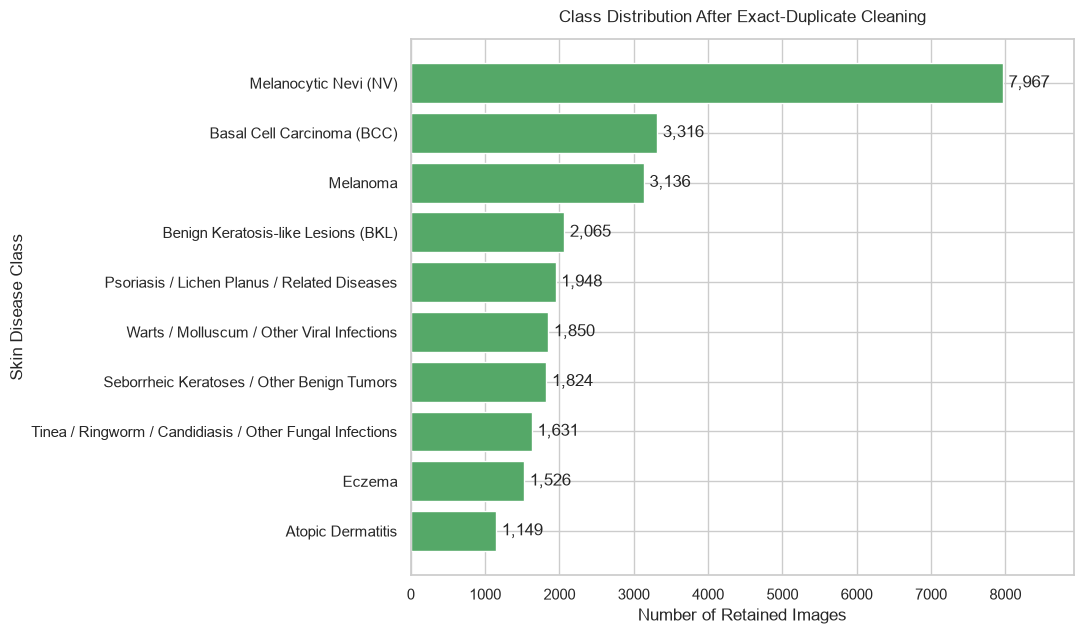

In [6]:
modeling_manifest = base_manifest.loc[base_manifest["include"]].copy()
near_group_by_path = (
    refined_near_duplicates.set_index("relative_path")["near_duplicate_group"]
    if not refined_near_duplicates.empty
    else pd.Series(dtype="object")
)
modeling_manifest["near_duplicate_group"] = modeling_manifest["relative_path"].map(
    near_group_by_path
)
modeling_manifest["group_id"] = modeling_manifest["near_duplicate_group"]
independent_mask = modeling_manifest["group_id"].isna()
modeling_manifest.loc[independent_mask, "group_id"] = (
    "INDEPENDENT_" + modeling_manifest.loc[independent_mask, "sha256"]
)
if not modeling_manifest.loc[independent_mask, "group_id"].is_unique:
    raise RuntimeError("Independent images did not receive unique group identifiers.")
modeling_manifest = modeling_manifest.rename(columns={"clean_class": "class_name"})
modeling_manifest = modeling_manifest[
    [
        "relative_path",
        "class_name",
        "class_id",
        "original_class",
        "width",
        "height",
        "aspect_ratio",
        "image_mode",
        "file_size_kb",
        "sha256",
        "exact_duplicate_group",
        "near_duplicate_group",
        "group_id",
    ]
].sort_values("relative_path", ignore_index=True)

final_class_distribution = (
    modeling_manifest.groupby(["class_id", "class_name"])
    .size()
    .rename("image_count")
    .reset_index()
    .sort_values("class_id")
)
final_class_distribution["percentage"] = (
    100 * final_class_distribution["image_count"] / len(modeling_manifest)
)

print(f"Original images: {len(base_manifest):,}")
print(f"Excluded images: {excluded_image_count:,}")
print(f"Final modeling images: {len(modeling_manifest):,}")
display(final_class_distribution)

plot_distribution = final_class_distribution.sort_values("image_count")
fig, ax = plt.subplots(figsize=(11, 6.5))
bars = ax.barh(
    plot_distribution["class_name"],
    plot_distribution["image_count"],
    color=sns.color_palette("deep")[2],
)
ax.bar_label(
    bars,
    labels=[f"{value:,}" for value in plot_distribution["image_count"]],
    padding=4,
)
ax.set_title("Class Distribution After Exact-Duplicate Cleaning", pad=12)
ax.set_xlabel("Number of Retained Images")
ax.set_ylabel("Skin Disease Class")
ax.margins(x=0.12)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "02_cleaned_class_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 7. Group-Aware Train / Validation / Test Split

Twenty shuffled stratified group folds are constructed with seed 42. Fourteen folds form the training subset, three form validation, and three form the frozen test subset. This approximates 70%/15%/15% while ensuring that each `group_id` is assigned to exactly one subset.

In [7]:
N_SPLIT_FOLDS = 20
TARGET_SPLIT_PROPORTIONS = {"train": 0.70, "validation": 0.15, "test": 0.15}

splitter = StratifiedGroupKFold(
    n_splits=N_SPLIT_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED,
)
fold_assignment = np.full(len(modeling_manifest), -1, dtype=np.int16)
placeholder_features = np.zeros((len(modeling_manifest), 1), dtype=np.uint8)

for fold_number, (_, fold_indices) in enumerate(
    splitter.split(
        placeholder_features,
        modeling_manifest["class_id"],
        groups=modeling_manifest["group_id"],
    )
):
    fold_assignment[fold_indices] = fold_number

if (fold_assignment < 0).any():
    raise RuntimeError("At least one retained image was not assigned to a fold.")

modeling_manifest["fold"] = fold_assignment
modeling_manifest["split"] = np.select(
    [
        modeling_manifest["fold"] < 14,
        modeling_manifest["fold"] < 17,
    ],
    ["train", "validation"],
    default="test",
)
modeling_manifest["split"] = pd.Categorical(
    modeling_manifest["split"],
    categories=["train", "validation", "test"],
    ordered=True,
)

## 8. Split Integrity Verification

The checks below are mandatory. Any path, exact hash, near-duplicate group, or general group appearing in more than one subset causes execution to stop.

Split summary:


,split,image_count,percentage,target_percentage,absolute_deviation_pp
0,train,18491,70.010,70.000,0.010
1,validation,3961,14.997,15.000,0.003
2,test,3960,14.993,15.000,0.007


Class counts by split:


split,train,validation,test
class_name,,,
Atopic Dermatitis,804,171,174
Basal Cell Carcinoma (BCC),2323,497,496
Benign Keratosis-like Lesions (BKL),1446,310,309
Eczema,1068,228,230
Melanocytic Nevi (NV),5577,1195,1195
Melanoma,2195,471,470
Psoriasis / Lichen Planus / Related Diseases,1365,292,291
Seborrheic Keratoses / Other Benign Tumors,1278,273,273
Tinea / Ringworm / Candidiasis / Other Fungal Infections,1143,245,243


Class percentages within each split:


split,train,validation,test
class_name,,,
Atopic Dermatitis,4.350,4.320,4.390
Basal Cell Carcinoma (BCC),12.560,12.550,12.530
Benign Keratosis-like Lesions (BKL),7.820,7.830,7.800
Eczema,5.780,5.760,5.810
Melanocytic Nevi (NV),30.160,30.170,30.180
Melanoma,11.870,11.890,11.870
Psoriasis / Lichen Planus / Related Diseases,7.380,7.370,7.350
Seborrheic Keratoses / Other Benign Tumors,6.910,6.890,6.890
Tinea / Ringworm / Candidiasis / Other Fungal Infections,6.180,6.190,6.140


Maximum absolute class-proportion deviation: 0.044 percentage points
Exact-hash leakage across splits: 0
Near-duplicate-group leakage across splits: 0
Group leakage across splits: 0


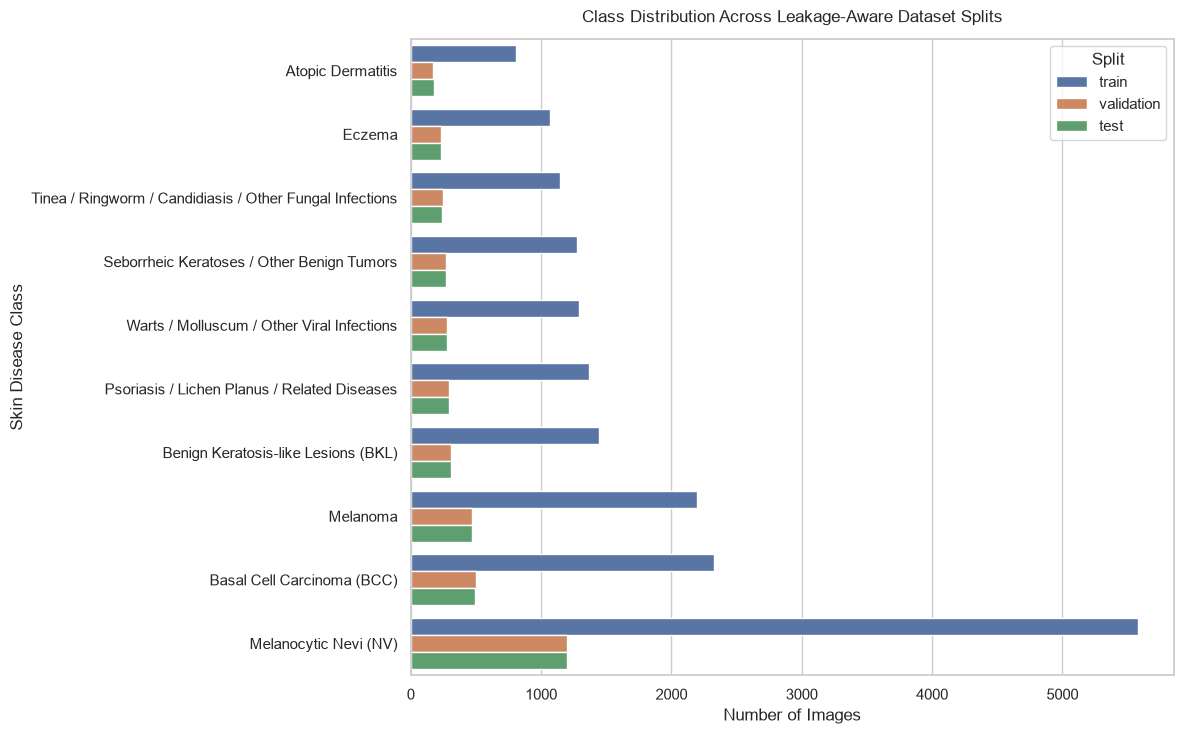

In [8]:
assert len(modeling_manifest) == retained_image_count
assert modeling_manifest["relative_path"].is_unique
assert not modeling_manifest["split"].isna().any()
assert modeling_manifest["class_id"].nunique() == len(CLEAN_CLASS_LABELS)

paths_by_split = {
    split_name: set(
        modeling_manifest.loc[modeling_manifest["split"] == split_name, "relative_path"]
    )
    for split_name in TARGET_SPLIT_PROPORTIONS
}
assert paths_by_split["train"].isdisjoint(paths_by_split["validation"])
assert paths_by_split["train"].isdisjoint(paths_by_split["test"])
assert paths_by_split["validation"].isdisjoint(paths_by_split["test"])
assert set().union(*paths_by_split.values()) == set(modeling_manifest["relative_path"])

exact_hash_leakage = int(
    (modeling_manifest.groupby("sha256", observed=True)["split"].nunique() > 1).sum()
)
near_duplicate_leakage = int(
    (
        modeling_manifest.dropna(subset=["near_duplicate_group"])
        .groupby("near_duplicate_group", observed=True)["split"]
        .nunique()
        > 1
    ).sum()
)
group_leakage = int(
    (modeling_manifest.groupby("group_id", observed=True)["split"].nunique() > 1).sum()
)

if exact_hash_leakage or near_duplicate_leakage or group_leakage:
    raise RuntimeError(
        "Duplicate-group leakage detected: "
        f"exact hashes={exact_hash_leakage}, "
        f"near-duplicate groups={near_duplicate_leakage}, groups={group_leakage}."
    )

class_presence = pd.crosstab(
    modeling_manifest["split"], modeling_manifest["class_id"], dropna=False
)
if (class_presence == 0).any().any():
    raise RuntimeError("At least one class is missing from a dataset split.")

split_summary = (
    modeling_manifest.groupby("split", observed=False)
    .size()
    .rename("image_count")
    .reset_index()
)
split_summary["percentage"] = 100 * split_summary["image_count"] / len(modeling_manifest)
split_summary["target_percentage"] = split_summary["split"].astype(str).map(
    {name: 100 * value for name, value in TARGET_SPLIT_PROPORTIONS.items()}
)
split_summary["absolute_deviation_pp"] = (
    split_summary["percentage"] - split_summary["target_percentage"]
).abs()
if (split_summary["absolute_deviation_pp"] > 2.0).any():
    raise RuntimeError("At least one split differs from its target size by more than 2 percentage points.")

class_counts_by_split = pd.crosstab(
    modeling_manifest["class_name"], modeling_manifest["split"], dropna=False
).reindex(columns=["train", "validation", "test"])
class_percentages_by_split = 100 * class_counts_by_split.div(
    class_counts_by_split.sum(axis=0), axis=1
)
overall_class_percentages = 100 * modeling_manifest["class_name"].value_counts(
    normalize=True
)
maximum_class_deviation_pp = float(
    class_percentages_by_split.sub(overall_class_percentages, axis=0).abs().max().max()
)
if maximum_class_deviation_pp > 2.0:
    raise RuntimeError(
        "Class proportions differ from the complete retained dataset by more than "
        "2 percentage points in at least one split."
    )

print("Split summary:")
display(split_summary)
print("Class counts by split:")
display(class_counts_by_split)
print("Class percentages within each split:")
display(class_percentages_by_split.round(2))
print(f"Maximum absolute class-proportion deviation: {maximum_class_deviation_pp:.3f} percentage points")
print(f"Exact-hash leakage across splits: {exact_hash_leakage}")
print(f"Near-duplicate-group leakage across splits: {near_duplicate_leakage}")
print(f"Group leakage across splits: {group_leakage}")

split_plot_data = (
    modeling_manifest.groupby(["class_name", "split"], observed=False)
    .size()
    .rename("image_count")
    .reset_index()
)
class_order = final_class_distribution.sort_values("image_count")["class_name"].tolist()
fig, ax = plt.subplots(figsize=(12, 7.5))
sns.barplot(
    data=split_plot_data,
    y="class_name",
    x="image_count",
    hue="split",
    order=class_order,
    hue_order=["train", "validation", "test"],
    ax=ax,
)
ax.set_title("Class Distribution Across Leakage-Aware Dataset Splits", pad=12)
ax.set_xlabel("Number of Images")
ax.set_ylabel("Skin Disease Class")
ax.legend(title="Split")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "02_split_class_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 9. Image-Property Distribution Across Splits

Medians and interquartile ranges summarize whether one subset contains a visibly different resolution or aspect-ratio distribution.

In [9]:
property_rows = []
for split_name, group in modeling_manifest.groupby("split", observed=False):
    row = {"split": split_name, "image_count": len(group)}
    for column in ["width", "height", "aspect_ratio"]:
        row[f"median_{column}"] = group[column].median()
        row[f"q1_{column}"] = group[column].quantile(0.25)
        row[f"q3_{column}"] = group[column].quantile(0.75)
    property_rows.append(row)

split_property_summary = pd.DataFrame(property_rows)
display(split_property_summary)

relative_median_ranges = {}
for column in ["width", "height", "aspect_ratio"]:
    medians = split_property_summary[f"median_{column}"]
    relative_median_ranges[column] = float(
        (medians.max() - medians.min()) / medians.median()
    )

print(
    "Relative ranges of split medians — "
    + ", ".join(
        f"{name}: {value:.2%}" for name, value in relative_median_ranges.items()
    )
)
if max(relative_median_ranges.values()) <= 0.10:
    print("No strong difference is visible among split medians for the audited image properties.")
else:
    print(
        "At least one image-property median differs by more than 10% across splits; "
        "this distribution should be considered during later evaluation."
    )

,split,image_count,median_width,q1_width,q3_width,median_height,q1_height,q3_height,median_aspect_ratio,q1_aspect_ratio,q3_aspect_ratio
0,train,18491,600.000,512.000,720.000,480.000,450.000,716.000,1.333,1.000,1.481
1,validation,3961,600.000,512.000,720.000,480.000,450.000,720.000,1.333,1.000,1.466
2,test,3960,600.000,592.000,720.000,480.000,450.000,685.000,1.333,1.000,1.488


Relative ranges of split medians — width: 0.00%, height: 0.00%, aspect_ratio: 0.00%
No strong difference is visible among split medians for the audited image properties.


## 10. Save Final Split Manifests

All stored paths remain portable and project-relative. The manifests reference raw images without copying or altering them.

In [10]:
manifest_columns = [
    "relative_path",
    "class_name",
    "class_id",
    "group_id",
    "split",
    "fold",
    "width",
    "height",
    "aspect_ratio",
    "image_mode",
    "file_size_kb",
    "sha256",
    "exact_duplicate_group",
    "near_duplicate_group",
]

dataset_manifest = modeling_manifest[manifest_columns].copy()
dataset_manifest["split"] = dataset_manifest["split"].astype(str)
dataset_manifest.to_csv(
    PROCESSED_DIR / "dataset_manifest.csv", index=False, encoding="utf-8"
)

split_filenames = {
    "train": "train.csv",
    "validation": "validation.csv",
    "test": "test.csv",
}
for split_name, filename in split_filenames.items():
    split_manifest = dataset_manifest.loc[
        dataset_manifest["split"] == split_name
    ].reset_index(drop=True)
    split_manifest.to_csv(PROCESSED_DIR / filename, index=False, encoding="utf-8")

split_summary.to_csv(
    REPORTS_DIR / "02_split_distribution.csv", index=False, encoding="utf-8"
)

saved_row_counts = {
    "train": len(pd.read_csv(PROCESSED_DIR / "train.csv")),
    "validation": len(pd.read_csv(PROCESSED_DIR / "validation.csv")),
    "test": len(pd.read_csv(PROCESSED_DIR / "test.csv")),
}
if sum(saved_row_counts.values()) != len(dataset_manifest):
    raise RuntimeError("Saved split manifests do not reconstruct the complete retained manifest.")

print(f"Saved complete manifest: {PROCESSED_DIR / 'dataset_manifest.csv'}")
for split_name, filename in split_filenames.items():
    print(f"Saved {split_name} manifest: {PROCESSED_DIR / filename} ({saved_row_counts[split_name]:,} rows)")
print(f"Saved split summary: {REPORTS_DIR / '02_split_distribution.csv'}")

Saved complete manifest: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\processed\dataset_manifest.csv
Saved train manifest: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\processed\train.csv (18,491 rows)
Saved validation manifest: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\processed\validation.csv (3,961 rows)
Saved test manifest: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\processed\test.csv (3,960 rows)
Saved split summary: C:\Projekt konferencyjny Turcja\skin-disease-classification\reports\02_split_distribution.csv


## 11. Final Validation Report

In [11]:
split_count_lookup = split_summary.set_index("split")["image_count"].to_dict()
final_validation_report = pd.DataFrame(
    {
        "metric": [
            "Original images",
            "Images excluded",
            "Images retained",
            "Training images",
            "Validation images",
            "Test images",
            "Number of classes",
            "Exact-hash leakage across splits",
            "Near-duplicate-group leakage across splits",
            "Group leakage across splits",
        ],
        "value": [
            len(base_manifest),
            excluded_image_count,
            len(modeling_manifest),
            int(split_count_lookup["train"]),
            int(split_count_lookup["validation"]),
            int(split_count_lookup["test"]),
            modeling_manifest["class_id"].nunique(),
            exact_hash_leakage,
            near_duplicate_leakage,
            group_leakage,
        ],
    }
)
display(final_validation_report)

if any([exact_hash_leakage, near_duplicate_leakage, group_leakage]):
    raise RuntimeError("The dataset is not ready because at least one leakage check failed.")
print("All known duplicate-group leakage checks passed.")

,metric,value
0,Original images,27153
1,Images excluded,741
2,Images retained,26412
3,Training images,18491
4,Validation images,3961
5,Test images,3960
6,Number of classes,10
7,Exact-hash leakage across splits,0
8,Near-duplicate-group leakage across splits,0
9,Group leakage across splits,0


All known duplicate-group leakage checks passed.


## Dataset Preparation Summary

In [12]:
split_percent_lookup = split_summary.set_index("split")["percentage"].to_dict()
preparation_summary = f"""
The logical cleaning procedure retained one deterministic representative from each same-class exact-duplicate group and excluded {same_class_excluded:,} redundant copies. All {cross_class_excluded:,} images belonging to byte-identical cross-class conflict groups were excluded rather than assigning an arbitrary label. The refined representative-based perceptual analysis identified {refined_group_count:,} high-confidence near-duplicate candidate groups involving {refined_image_count:,} images; their members share a split group, and {cross_class_refined_groups:,} group(s) span more than one class and remain flagged for inspection.

The final modeling manifest contains {len(modeling_manifest):,} images. The achieved allocation is {split_percent_lookup['train']:.2f}% training, {split_percent_lookup['validation']:.2f}% validation, and {split_percent_lookup['test']:.2f}% test. Exact hashes, refined near-duplicate groups, and general grouping identifiers each have zero observed cross-split leakage. This is a leakage-reduced split; the test subset is frozen for final evaluation and must not be used for model selection.
"""
display(Markdown(preparation_summary))


The logical cleaning procedure retained one deterministic representative from each same-class exact-duplicate group and excluded 501 redundant copies. All 240 images belonging to byte-identical cross-class conflict groups were excluded rather than assigning an arbitrary label. The refined representative-based perceptual analysis identified 111 high-confidence near-duplicate candidate groups involving 230 images; their members share a split group, and 10 group(s) span more than one class and remain flagged for inspection.

The final modeling manifest contains 26,412 images. The achieved allocation is 70.01% training, 15.00% validation, and 14.99% test. Exact hashes, refined near-duplicate groups, and general grouping identifiers each have zero observed cross-split leakage. This is a leakage-reduced split; the test subset is frozen for final evaluation and must not be used for model selection.


### Remaining Limitations

Reliable patient-level and lesion-level identifiers are not available for all images. Consequently, exact-hash and perceptual-similarity controls cannot guarantee true patient-level independence between subsets. The dataset also contains heterogeneous acquisition styles and visible source artifacts, including watermarks in some images. These properties may provide shortcut-learning cues and should be considered during preprocessing design, model interpretation, and final evaluation.

No model training, augmentation, tensor normalization, or image resizing is performed in this notebook. The raw dataset remains unchanged.